# Portfolio Optimization with Modern Portfolio Theory

## Overview
This project uses Markowitz's Modern Portfolio Theory to build data-driven portfolios from historical price data. Instead of guessing an allocation, it runs a Monte Carlo simulation over thousands of random weight combinations and picks the one with the best risk-adjusted return.

This started as a crypto only analysis, but the underlying math doesn't care what kind of asset it's looking at. It was later generalized to work with any ticker available on Yahoo Finance, so the same code can price a crypto portfolio, a basket of B3 stocks, or a mix of both.

### What it does
* Simulates 100,000 random portfolios to map the risk-return trade-off
* Finds the efficient frontier: the best possible return for each level of risk
* Caps any single asset at 40% of the portfolio to force diversification


## Setup

Four libraries do the work:
* `yfinance` downloads historical price data
* `numpy` handles the matrix math behind the simulations
* `pandas` manages the price and returns tables
* `matplotlib` plots the efficient frontier


In [ ]:
# To fetch historical price data from Yahoo Finance
%pip install yfinance 

# To handle the data tables (DataFrames)
%pip install pandas 

# To perform the heavy math and matrix multiplications
%pip install numpy 

# To create the actual Markowitz graph
%pip install matplotlib


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt


## Data Acquisition

First step: pull historical prices for the tickers we care about. We only need the Close price for the calculations that follow.

Tickers can be anything Yahoo Finance recognizes: crypto (`BTC-USD`), US stocks (`AAPL`), or B3 stocks (`PETR4.SA`, `VALE3.SA`, `ITUB4.SA`).


In [3]:
tickers = ['PETR4.SA', 'VALE3.SA', 'ITUB4.SA', 'WEGE3.SA']
start_date = '2020-01-01'
end_date = '2025-12-31'
data = yf.download(tickers, start=start_date, end=end_date)['Close']
data.head()


[                       0%                       ]

[**********************50%                       ]  2 of 4 completed

[**********************75%***********            ]  3 of 4 completed

[*********************100%***********************]  4 of 4 completed

Ticker,ITUB4.SA,PETR4.SA,VALE3.SA,WEGE3.SA
Date,,,,
2020-01-02,22.946228,8.289424,29.317493,15.458446
2020-01-03,22.704870,8.221920,29.101648,15.261045
2020-01-06,22.366985,8.319124,28.928972,15.300525
2020-01-07,21.848089,8.286725,29.139421,15.418967
2020-01-08,21.492098,8.235422,29.144815,14.835546


## Handling Missing Data

Not every asset trades on the same calendar. Crypto trades every day of the year, while B3 and other stock exchanges only trade on business days, so mixing them produces `NaN` values wherever one asset has a price and another doesn't. Left unfiltered, these gaps distort the mean returns and, more noticeably, the covariance matrix, since a single misaligned asset can throw off its correlation with every other asset in the portfolio.

We handle this in two steps:
1. **Drop tickers with too much missing data.** If an asset is missing more than 10% of its prices (for example, it started trading later than the others), it's excluded rather than silently corrupting the rest of the dataset.
2. **Forward-fill remaining gaps.** For minor mismatches, like a stock exchange holiday that isn't a crypto holiday, we carry the last known price forward instead of dropping the whole row across every asset.


In [4]:
# Check how much data is missing per ticker
missing_pct = data.isna().mean()
print("Missing data by ticker:\n", missing_pct, "\n")

# Drop tickers with excessive missing data instead of letting them shrink the whole dataset
tickers_to_drop = missing_pct[missing_pct > 0.10].index.tolist()
if tickers_to_drop:
    print(f"Dropping tickers with more than 10% missing data: {tickers_to_drop}")
    data = data.drop(columns=tickers_to_drop)
    tickers = [t for t in tickers if t not in tickers_to_drop]

# Forward-fill small calendar mismatches, then drop any leading rows still missing data
data = data.ffill().dropna()

print(f"Final dataset: {data.shape[0]} trading days across {data.shape[1]} tickers")
data.head()


Missing data by ticker:
 Ticker
ITUB4.SA    0.0
PETR4.SA    0.0
VALE3.SA    0.0
WEGE3.SA    0.0
dtype: float64 

Final dataset: 1494 trading days across 4 tickers


Ticker,ITUB4.SA,PETR4.SA,VALE3.SA,WEGE3.SA
Date,,,,
2020-01-02,22.946228,8.289424,29.317493,15.458446
2020-01-03,22.704870,8.221920,29.101648,15.261045
2020-01-06,22.366985,8.319124,28.928972,15.300525
2020-01-07,21.848089,8.286725,29.139421,15.418967
2020-01-08,21.492098,8.235422,29.144815,14.835546


## Daily Returns

Prices on their own don't compare well across assets (a $500 stock and a $0.40 token aren't on the same scale), so we work with returns instead.

We use log returns instead of simple percentage returns. Log returns are additive across time (the return over 5 days is just the sum of the 5 daily log returns), which is what the annualization and covariance math further down assumes.

**Formula:** $\text{Return} = \ln\left(\frac{\text{Price}_{\text{today}}}{\text{Price}_{\text{yesterday}}}\right)$

The first row has no prior day to compare against, so it comes out as `NaN`. `dropna()` removes it.


In [5]:
# Log returns: ln(Price_today / Price_yesterday), additive over time unlike simple percentage returns
returns = np.log(data / data.shift(1)).dropna()

print(returns.head())


Ticker      ITUB4.SA  PETR4.SA  VALE3.SA  WEGE3.SA
Date                                              
2020-01-03 -0.010574 -0.008177 -0.007390 -0.012852
2020-01-06 -0.014993  0.011753 -0.005951  0.002584
2020-01-07 -0.023473 -0.003902  0.007248  0.007711
2020-01-08 -0.016428 -0.006210  0.000185 -0.038572
2020-01-09 -0.020134 -0.003284 -0.013233 -0.014895


## Mean Returns and Covariance

Two numbers drive the model:

**Mean returns**: the average daily return per asset, annualized by multiplying by 252 trading days. This is the expected reward.

**Covariance matrix**: how each pair of assets moves relative to the others. Assets that move together add less diversification benefit than assets that move independently or inversely.

Portfolio risk isn't just the average risk of its parts, it depends heavily on these correlations. Combining assets that don't move in lockstep can lower total risk without giving up return.


In [6]:
# Average daily return for each token
mean_returns = returns.mean()
print("Mean Returns:\n", mean_returns, "\n")

# Covariance matrix (The risk relationship between tokens)
cov_matrix = returns.cov()
print("Covariance Matrix:\n", cov_matrix, "\n")


Mean Returns:
 Ticker
ITUB4.SA    0.000345
PETR4.SA    0.000838
VALE3.SA    0.000583
WEGE3.SA    0.000762
dtype: float64 

Covariance Matrix:
 Ticker    ITUB4.SA  PETR4.SA  VALE3.SA  WEGE3.SA
Ticker                                          
ITUB4.SA  0.000371  0.000252  0.000153  0.000128
PETR4.SA  0.000252  0.000726  0.000274  0.000201
VALE3.SA  0.000153  0.000274  0.000491  0.000134
WEGE3.SA  0.000128  0.000201  0.000134  0.000545 



## Portfolio Return, Risk, and Sharpe Ratio

**Portfolio return** is the weighted average of each asset's return:
$$R_p = \sum_{i=1}^{n} w_i \mu_i$$
`np.dot(weights, mean_returns) * 252`

**Portfolio risk** accounts for how assets move together, not just their individual volatility:
$$\sigma_p = \sqrt{w^T \Sigma w}$$
`np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))`

**Sharpe ratio** measures return per unit of risk:
$$Sharpe = \frac{R_p - R_f}{\sigma_p}$$

We assume a risk-free rate of 0 for simplicity.


In [7]:
# Step A: Create random weights that sum to 1
weights = np.random.random(len(tickers))
weights /= np.sum(weights)

# Step B: Calculate Annualized Return
# (Daily Return * 252 trading days)
p_ret = np.dot(weights, mean_returns) * 252

# Step C: Calculate Annualized Volatility (Risk)
# Formula: sqrt(Weights * Covariance * Weights) * sqrt(252)
p_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))

print(f"Random Weights: {weights}")
print(f"Expected Annual Return: {p_ret:.2%}")
print(f"Expected Annual Risk: {p_vol:.2%}")


Random Weights: [0.31952473 0.36529112 0.09071973 0.22446442]
Expected Annual Return: 16.14%
Expected Annual Risk: 27.90%


## Monte Carlo Simulation

There's no closed-form way to pick the best weights across multiple assets, so we brute-force it: generate 100,000 random weight combinations, calculate return and risk for each, and see where they land. Plotting all of them traces out the efficient frontier.


## Concentration Limit

Left unconstrained, the simulation tends to favor a single asset with the best historical return, which isn't a real diversification strategy. We cap each asset at 40% of the portfolio: any random weight set that exceeds this gets discarded and re-rolled until it passes.


In [8]:
# 1. Initialization
num_portfolios = 100000  # Note: 100k portfolios will take a few seconds
num_assets = len(tickers)

all_weights = np.zeros((num_portfolios, num_assets))
ret_arr = np.zeros(num_portfolios)
vol_arr = np.zeros(num_portfolios)
sharpe_arr = np.zeros(num_portfolios)

# 2. The Simulation Loop
for i in range(num_portfolios):
    
    # Step A: Generate Random Weights that sum to 1 with 40% Concentration Limit
    valid_portfolio = False
    while not valid_portfolio:
        weights = np.random.random(num_assets)
        weights /= np.sum(weights)
        
        # Applying the 40% Concentration Limit
        if np.max(weights) <= 0.40:
            valid_portfolio = True

    all_weights[i,:] = weights
    
    # Step B: Calculate Annualized Return (R_p)
    portfolio_return = np.dot(weights, mean_returns) * 252
    ret_arr[i] = portfolio_return
    
    # Step C: Calculate Annualized Volatility (sigma_p)
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))
    vol_arr[i] = portfolio_volatility
    
    # Step D: Calculate Sharpe Ratio
    sharpe_arr[i] = ret_arr[i] / vol_arr[i]

# 3. Frontier calculation
# Sorting results to find the "edge" of the cloud
idx = np.argsort(vol_arr)
vol_sorted = vol_arr[idx]
ret_sorted = ret_arr[idx]

frontier_vol = []
frontier_ret = []

max_ret = -np.inf
for v, r in zip(vol_sorted, ret_sorted):
    if r > max_ret:
        frontier_vol.append(v)
        frontier_ret.append(r)
        max_ret = r

print("Monte Carlo Simulation with 40% constraint complete.")


Monte Carlo Simulation with 40% constraint complete.


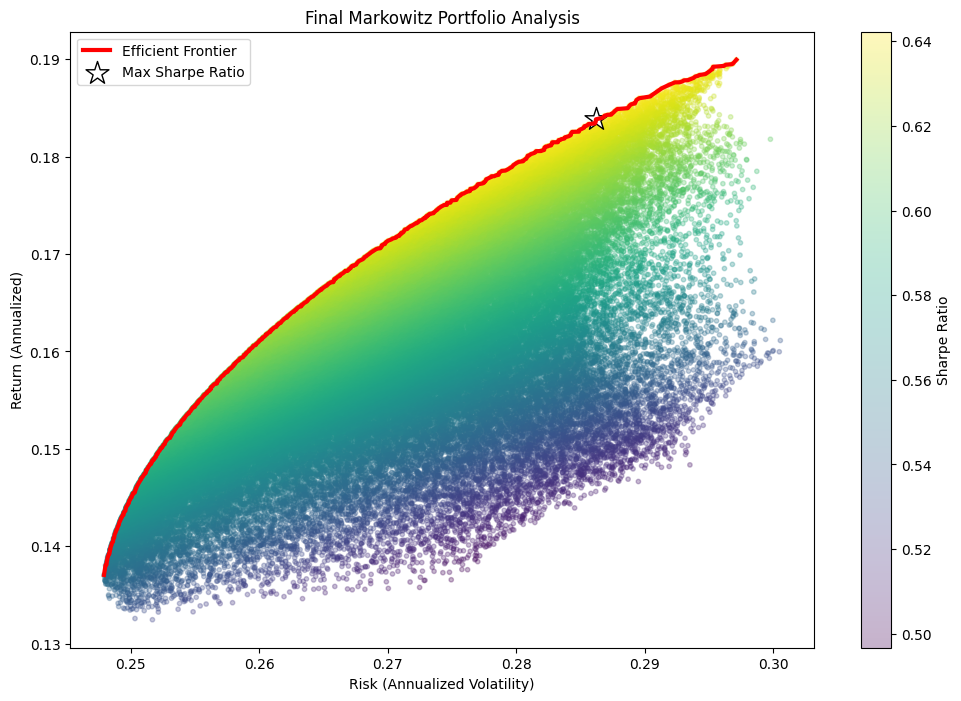

PETR4.SA: 1.51%
VALE3.SA: 30.89%
ITUB4.SA: 27.71%
WEGE3.SA: 39.88%


In [9]:
plt.figure(figsize=(12, 8))

# 1. The Cloud (All portfolios)
plt.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='viridis', alpha=0.3, s=10)
plt.colorbar(label='Sharpe Ratio')

# 2. The Frontier Line (The logic you just wrote!)
plt.plot(frontier_vol, frontier_ret, color='red', linewidth=3, label='Efficient Frontier')

# 3. The Optimal Point
max_sharpe_idx = sharpe_arr.argmax()
plt.scatter(vol_arr[max_sharpe_idx], ret_arr[max_sharpe_idx], color='white', marker='*', s=300, edgecolors='black', label='Max Sharpe Ratio')

plt.title('Final Markowitz Portfolio Analysis')
plt.xlabel('Risk (Annualized Volatility)')
plt.ylabel('Return (Annualized)')
plt.legend()
plt.show()

# Display the optimal weights
optimal_weights = all_weights[max_sharpe_idx]
for i, ticker in enumerate(tickers):
    print(f"{ticker}: {optimal_weights[i]:.2%}")